# 🔐 Project: Phishing URL Detection Using SVM
## 1. Project Overview

Phishing URL Detection Using Support Vector Machine (SVM) is a machine learning classification project that aims to identify whether a given website URL is phishing or benign. The model learns patterns from different URL, link, security, certificate, and domain-related features and uses these patterns to classify new URLs.

## 2. Project Objective

The main objective of this project is to develop a machine learning model using Support Vector Machine (SVM) to classify URLs as phishing or benign based on their characteristics.

The project focuses on:

    - Understanding phishing URL characteristics
    - Cleaning and preparing the dataset
    - Performing exploratory data analysis
    - Selecting relevant features
    - Applying appropriate preprocessing techniques
    - Building an SVM classification model
    - Evaluating model performance
    - Tuning SVM hyperparameters
    - Using the final model to predict whether a URL is phishing or benign

## 3. Problem Statement

Phishing websites are fraudulent websites designed to imitate legitimate websites and deceive users into providing sensitive information. Detecting phishing websites manually can be difficult because phishing URLs may closely resemble legitimate URLs. Machine learning can help automate this process by learning patterns from URL and website-related features. This project uses an SVM classifier to distinguish between phishing and benign URLs.

## 4. Why This Project?

Phishing is an important cybersecurity problem because malicious websites can be used to obtain:

    - Login credentials
    - Banking information
    - Personal information
    - Payment information
    - Other sensitive data

Machine learning can analyze multiple characteristics of a website simultaneously and identify patterns associated with phishing websites.

# 📊 Dataset Description
## 5. Dataset Overview

The dataset contains information about URLs and several characteristics associated with the corresponding websites. These characteristics include link information, HTTP/HTTPS usage, IP-related information, iframe information, country and organization details, SSL certificate information, WHOIS information, and URL-based characteristics.

The dataset contains:

| Property       |              Details |
| -------------- | -------------------: |
| Total records  |              **800** |
| Total columns  |               **24** |
| Phishing URLs  |              **400** |
| Benign URLs    |              **400** |
| Target column  |           **`type`** |
| Target classes | **phishing, benign** |



The dataset is balanced, with an equal number of phishing and benign records.

## 6. Dataset Feature Description

You can put this table into a Markdown cell in your notebook.

| Feature                     | Description                                                                   |
| --------------------------- | ----------------------------------------------------------------------------- |
| `Link Density`              | Represents the density of links associated with the webpage.                  |
| `External Links Count`      | Number of links that point to external websites or domains.                   |
| `Internal Links Count`      | Number of links that point to pages within the same website.                  |
| `External IP Count`         | Number of links or references associated with external IP addresses.          |
| `HTTP Count`                | Number of HTTP references or links present on the webpage.                    |
| `HTTPS Count`               | Number of HTTPS references or links present on the webpage.                   |
| `Non Count`                 | Count of references that are not categorized as HTTP or HTTPS.                |
| `External Iframes Count`    | Number of iframe elements loaded from external sources.                       |
| `Hidden Iframes Count`      | Number of hidden iframe elements detected on the webpage.                     |
| `If HTTPS`                  | Indicates whether the website uses HTTPS.                                     |
| `Country`                   | Country associated with the website or domain.                                |
| `Organization`              | Organization associated with the domain or certificate information.           |
| `Certificate`               | Information related to the website's SSL/security certificate.                |
| `Whois_country`             | Country information obtained from WHOIS domain information.                   |
| `Certificate Validity Days` | Number of days between the certificate's validity start and expiration dates. |
| `Domain Validity Days`      | Number of days between the domain's WHOIS creation and expiration dates.      |
| `URL Length`                | Total number of characters in the URL.                                        |
| `URL Dot Count`             | Number of dots (`.`) present in the URL.                                      |
| `URL Hyphen Count`          | Number of hyphens (`-`) present in the URL.                                   |
| `URL Slash Count`           | Number of slash (`/`) characters present in the URL.                          |
| `URL Digit Count`           | Number of numerical digits present in the URL.                                |
| `URL Special Char Count`    | Number of special characters present in the URL.                              |
| `URL Has IP`                | Indicates whether the URL directly contains an IP address.                    |
| `type`                      | **Target variable indicating whether the URL is `phishing` or `benign`.**     |


# Data Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv(r"Data/phishing_url_svm_ready.csv")
data

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP,type
0,0.000000,0,0,0,0,0,0,0,0,1,...,89.999988,3653.0,104,5,0,8,1,22,0,phishing
1,0.366667,10,0,0,0,10,1,0,0,0,...,360.000000,NaN,58,2,2,4,0,10,0,benign
2,0.000000,0,0,0,0,0,0,0,0,0,...,NaN,4748.0,12,2,0,0,0,2,0,phishing
3,0.000000,0,0,0,0,0,0,0,0,0,...,365.000000,NaN,14,1,0,0,0,1,0,phishing
4,0.288032,102,0,0,2,93,44,1,1,0,...,89.999988,8401.0,73,2,1,2,12,12,0,benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0.000000,0,0,0,0,0,0,0,0,0,...,89.999988,3287.0,59,3,6,1,0,10,0,benign
796,0.136364,5,0,0,0,5,1,0,0,1,...,NaN,3652.0,81,3,3,7,1,14,0,phishing
797,0.087413,1,0,0,1,0,24,0,0,0,...,89.999988,9131.0,52,2,2,2,0,8,0,benign
798,0.341463,36,0,0,3,28,80,0,0,0,...,393.999988,8036.0,30,1,0,3,0,4,0,benign


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Link Density               800 non-null    float64
 1   External Links Count       800 non-null    int64  
 2   Internal Links Count       800 non-null    int64  
 3   External IP Count          800 non-null    int64  
 4   HTTP Count                 800 non-null    int64  
 5   HTTPS Count                800 non-null    int64  
 6   Non Count                  800 non-null    int64  
 7   External Iframes Count     800 non-null    int64  
 8   Hidden Iframes Count       800 non-null    int64  
 9   If HTTPS                   800 non-null    int64  
 10  Country                    800 non-null    object 
 11  Organization               800 non-null    object 
 12  Certificate                800 non-null    object 
 13  Whois_country              660 non-null    object 

In [4]:
data.duplicated().sum()

np.int64(7)

In [5]:
data.isna().sum()

Link Density                   0
External Links Count           0
Internal Links Count           0
External IP Count              0
HTTP Count                     0
HTTPS Count                    0
Non Count                      0
External Iframes Count         0
Hidden Iframes Count           0
If HTTPS                       0
Country                        0
Organization                   0
Certificate                    0
Whois_country                140
Certificate Validity Days    148
Domain Validity Days         454
URL Length                     0
URL Dot Count                  0
URL Hyphen Count               0
URL Slash Count                0
URL Digit Count                0
URL Special Char Count         0
URL Has IP                     0
type                           0
dtype: int64

In [6]:
data.shape

(800, 24)

In [7]:
data['type'].value_counts()

type
phishing    400
benign      400
Name: count, dtype: int64

In [8]:
data=data.drop_duplicates()

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data.shape

(793, 24)

In [11]:
data['type'].value_counts()

type
phishing    398
benign      395
Name: count, dtype: int64

| Property                                                  | Details              |
| -------------------------------                           | -------------------- |
| Rows before removing duplicates                           | 800                  |
| Phishing URLs before removing duplicates                  | 400                  |
| Benign URLs before removing duplicates                    | 400                  |
| Duplicate rows removed                                    | 7                    |
| **Current rows**                                          | **793**              |
| Columns                                                   | **24**               |
|**Currnet Phishing URLs**                                  | **398**              |
|**Current Benign URLs**                                    | **395**              |
| Numerical columns                                         | 19                   |
| Categorical columns                                       | 5                    |
| Columns with missing values                               | 3                    |
| Target column                                             | `type`               |
| Target values                                             | `phishing`, `benign` |

*Missing Values:*
Missing values are present in three feature columns: Whois_country, Certificate Validity Days, and Domain Validity Days. These missing values will be handled during preprocessing rather than removing the corresponding rows, so that useful observations are not unnecessarily lost.

In [12]:
data

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,...,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP,type
0,0.000000,0,0,0,0,0,0,0,0,1,...,89.999988,3653.0,104,5,0,8,1,22,0,phishing
1,0.366667,10,0,0,0,10,1,0,0,0,...,360.000000,NaN,58,2,2,4,0,10,0,benign
2,0.000000,0,0,0,0,0,0,0,0,0,...,NaN,4748.0,12,2,0,0,0,2,0,phishing
3,0.000000,0,0,0,0,0,0,0,0,0,...,365.000000,NaN,14,1,0,0,0,1,0,phishing
4,0.288032,102,0,0,2,93,44,1,1,0,...,89.999988,8401.0,73,2,1,2,12,12,0,benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0.000000,0,0,0,0,0,0,0,0,0,...,89.999988,3287.0,59,3,6,1,0,10,0,benign
796,0.136364,5,0,0,0,5,1,0,0,1,...,NaN,3652.0,81,3,3,7,1,14,0,phishing
797,0.087413,1,0,0,1,0,24,0,0,0,...,89.999988,9131.0,52,2,2,2,0,8,0,benign
798,0.341463,36,0,0,3,28,80,0,0,0,...,393.999988,8036.0,30,1,0,3,0,4,0,benign


In [13]:
data[['Whois_country',
      'Certificate Validity Days',
      'Domain Validity Days']].head(10)

,Whois_country,Certificate Validity Days,Domain Validity Days
0,CR,89.999988,3653.0
1,US,360.000000,NaN
2,IN,NaN,4748.0
3,US,365.000000,NaN
4,NaN,89.999988,8401.0
5,US,394.999988,9132.0
6,BR,89.999988,NaN
7,US,365.999988,NaN
8,CN,364.999988,2192.0
9,IN,NaN,4748.0


In [14]:
data[['Certificate Validity Days',
      'Domain Validity Days']].describe()

,Certificate Validity Days,Domain Validity Days
count,645.000000,344.000000
mean,169.582291,7001.933886
std,127.766254,3799.136896
min,29.999988,365.000000
25%,89.999988,4018.000000
50%,89.999988,7671.000000
75%,334.999988,10227.000000
max,397.000000,14245.958333


In [15]:
# Fill categorical missing values
data['Whois_country'] = data['Whois_country'].fillna('Unknown')

# Fill numerical missing values with median
data['Certificate Validity Days'] = data['Certificate Validity Days'].fillna(
    data['Certificate Validity Days'].median()
)

data['Domain Validity Days'] = data['Domain Validity Days'].fillna(
    data['Domain Validity Days'].median()
)

In [16]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 793 entries, 0 to 799
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Link Density               793 non-null    float64
 1   External Links Count       793 non-null    int64  
 2   Internal Links Count       793 non-null    int64  
 3   External IP Count          793 non-null    int64  
 4   HTTP Count                 793 non-null    int64  
 5   HTTPS Count                793 non-null    int64  
 6   Non Count                  793 non-null    int64  
 7   External Iframes Count     793 non-null    int64  
 8   Hidden Iframes Count       793 non-null    int64  
 9   If HTTPS                   793 non-null    int64  
 10  Country                    793 non-null    object 
 11  Organization               793 non-null    object 
 12  Certificate                793 non-null    object 
 13  Whois_country              793 non-null    object 
 14 

In [17]:
data.describe()

,Link Density,External Links Count,Internal Links Count,External IP Count,HTTP Count,HTTPS Count,Non Count,External Iframes Count,Hidden Iframes Count,If HTTPS,Certificate Validity Days,Domain Validity Days,URL Length,URL Dot Count,URL Hyphen Count,URL Slash Count,URL Digit Count,URL Special Char Count,URL Has IP
count,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000
mean,0.106346,14.480454,19.068096,0.022699,6.860025,25.670870,37.586381,0.235813,0.102144,0.211854,154.729604,7380.761989,47.646910,1.889029,1.321564,2.363178,4.122320,6.750315,0.001261
std,0.139278,46.373646,96.959577,0.507011,42.823744,99.157404,152.079509,0.737611,0.327074,0.408880,119.316191,2522.089511,39.980063,1.418775,2.889593,2.551343,9.094699,7.031545,0.035511
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,29.999988,365.000000,7.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89.999988,7671.000000,19.000000,1.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,0.054054,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,89.999988,7671.000000,36.000000,2.000000,0.000000,2.000000,0.000000,5.000000,0.000000
75%,0.169897,8.000000,5.000000,0.000000,1.000000,16.000000,17.000000,0.000000,0.000000,0.000000,90.999988,7671.000000,62.000000,2.000000,1.000000,4.000000,5.000000,9.000000,0.000000
max,1.053254,590.000000,2278.000000,14.000000,654.000000,2282.000000,2447.000000,10.000000,2.000000,1.000000,397.000000,14245.958333,290.000000,11.000000,22.000000,14.000000,91.000000,82.000000,1.000000


In [18]:
data.to_csv(r"Data/phishing_url_svm_ready_cleaned.csv", index=False)

# EDA

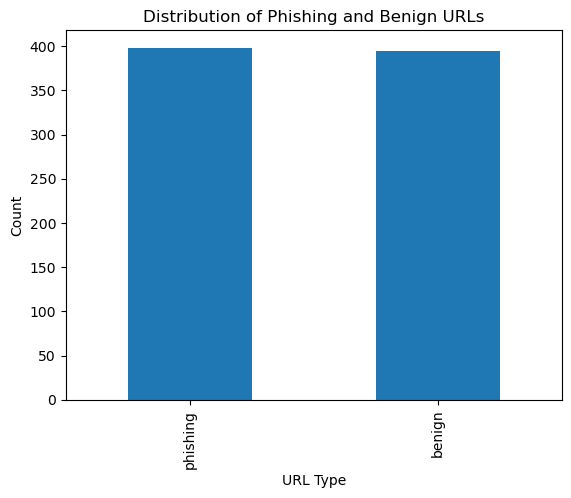

In [19]:
data['type'].value_counts().plot(kind='bar')

plt.xlabel('URL Type')
plt.ylabel('Count')
plt.title('Distribution of Phishing and Benign URLs')
plt.show()

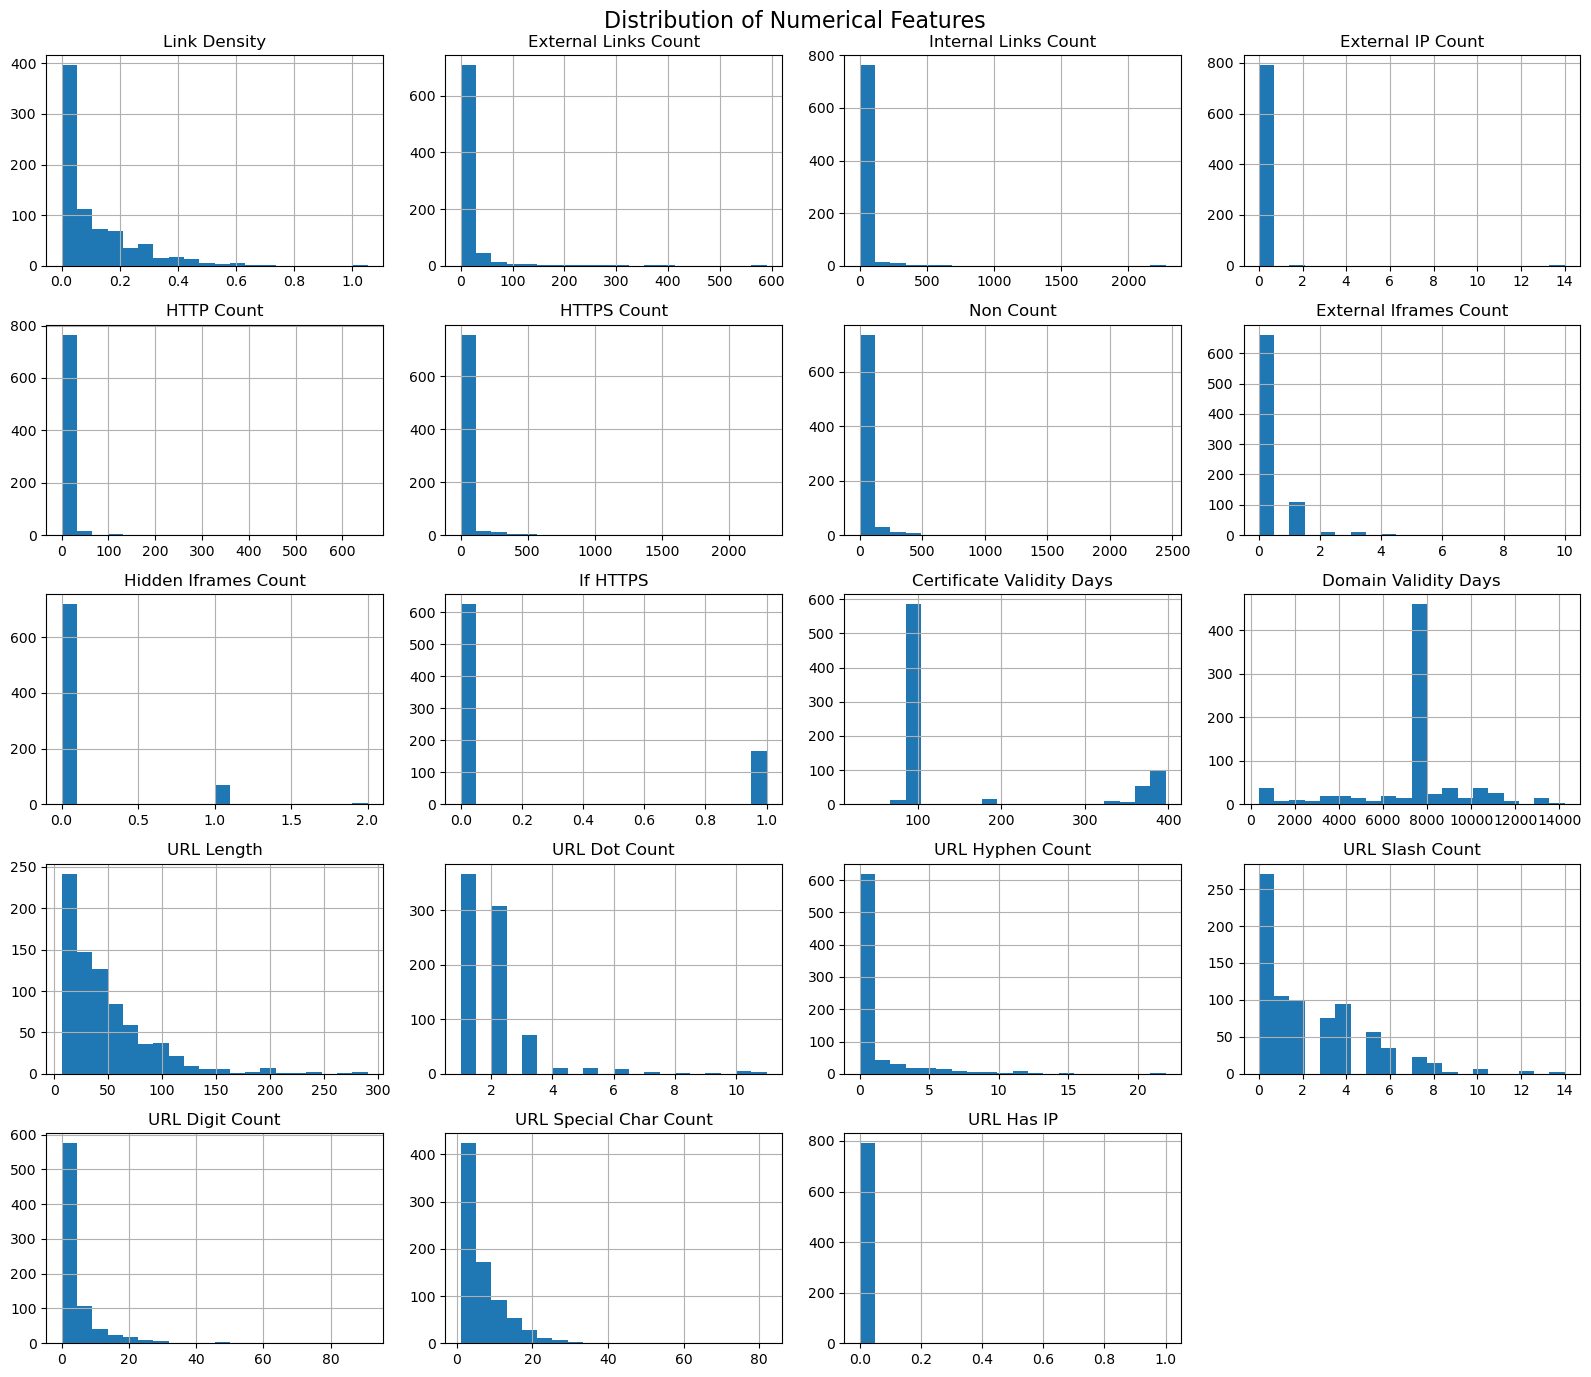

In [20]:
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns

data[numerical_features].hist(
    figsize=(16, 14),
    bins=20
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

### Insights
- Histograms were used to examine the distribution of the numerical features.
- Most features show a right-skewed distribution, with most observations concentrated at lower values and a smaller number of observations having higher values.
- Features such as `URL Length`, `External Links Count`, `Internal Links Count`, and `URL Digit Count` show noticeable variation. These distributions will be considered during preprocessing and model development.

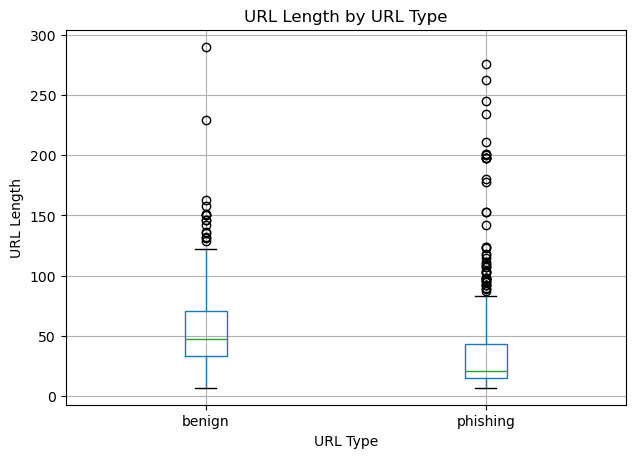

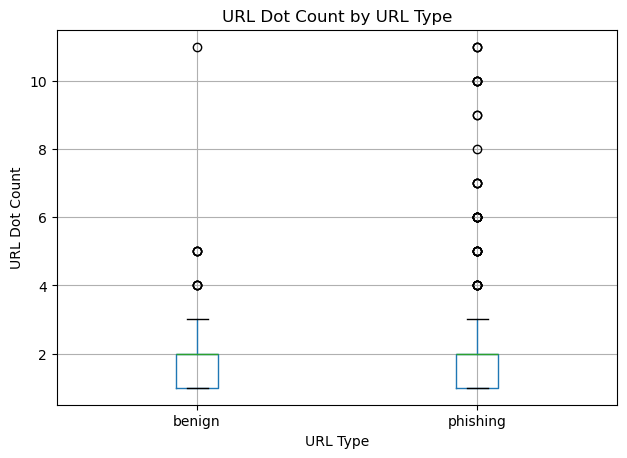

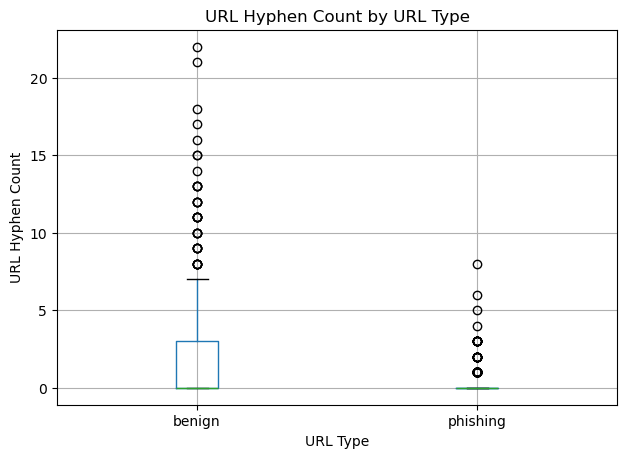

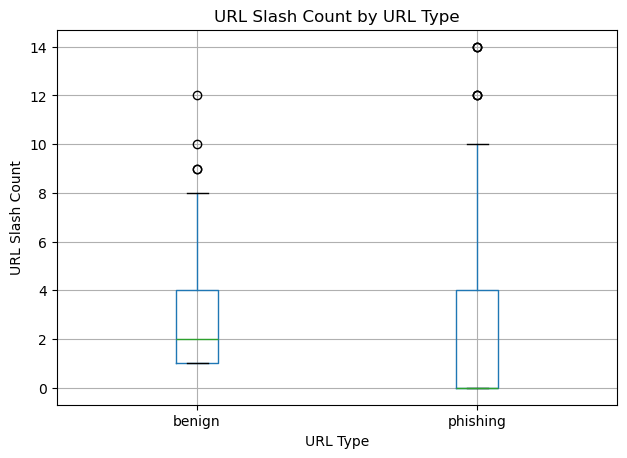

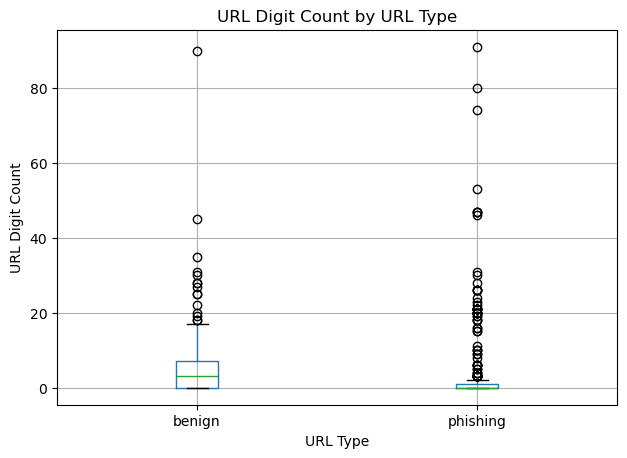

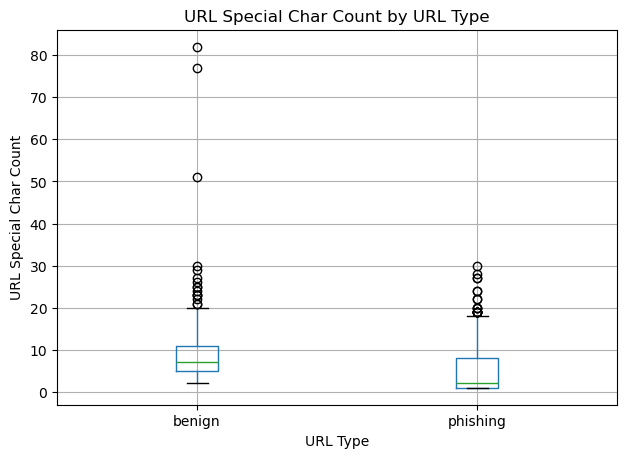

In [21]:
features = [
    'URL Length',
    'URL Dot Count',
    'URL Hyphen Count',
    'URL Slash Count',
    'URL Digit Count',
    'URL Special Char Count'
]

for feature in features:
    data.boxplot(column=feature, by='type', figsize=(7, 5))
    plt.title(f'{feature} by URL Type')
    plt.suptitle('')
    plt.xlabel('URL Type')
    plt.ylabel(feature)
    plt.show()

### Insights
- **URL Length**: Benign URLs have a higher median length, while phishing URLs have more high-value observations/outliers.
- **URL Dot Count**: Both classes have similar central distributions, with considerable overlap.
- **URL Hyphen Count**: Benign URLs have a higher spread and more extreme values.
- **URL Slash Count**: The two classes overlap considerably, although phishing URLs show a wider upper range.
- **URL Digit Count**: Benign URLs have a higher median, while phishing URLs contain many high-value outliers.
- **URL Special Char Count**: Benign URLs generally have a higher median and spread.

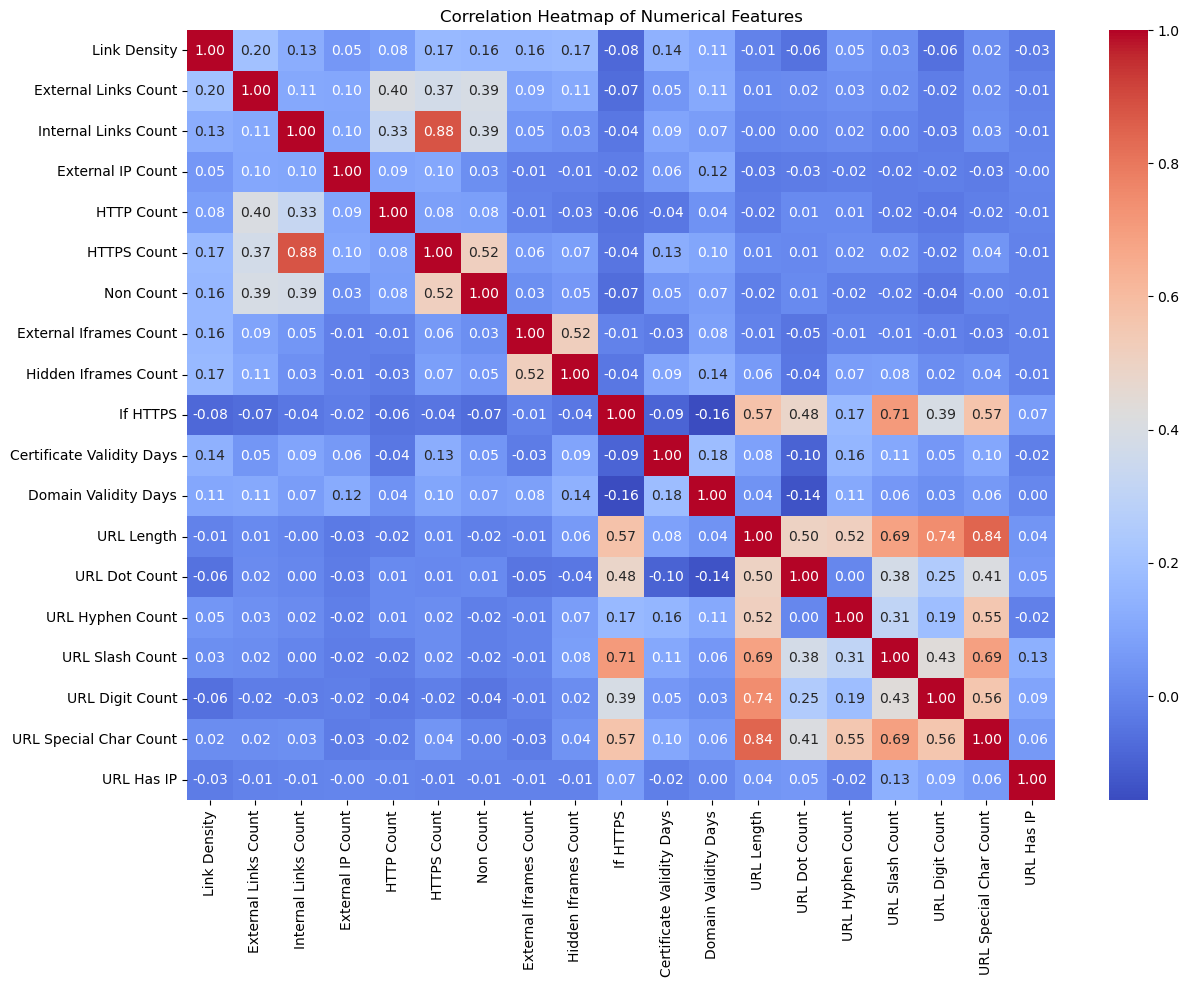

In [22]:
plt.figure(figsize=(14, 10))

correlation = data.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Insights
- Internal Links Count ↔ HTTPS Count = 0.88 → strong positive correlation.
- URL Length ↔ URL Special Char Count = 0.84 → strong positive correlation.
- URL Length ↔ URL Digit Count = 0.74 → strong positive correlation.
- If HTTPS ↔ URL Slash Count = 0.71 → moderately strong positive correlation.
- URL Length ↔ URL Slash Count = 0.69 → moderately strong positive correlation.
- URL Has IP has very weak correlation with most numerical features.